# Klasifikasi Soal LeetCode: Naive Bayes, SVM, dan Decision Tree

Bagian pertama dari dua notebook klasifikasi. Ketiga algoritma diuji pada dua dataset, yaitu Dataset I dengan target tingkat kesulitan yang single-label, dan Dataset II dengan target topik yang multi-label.

Tiga algoritma lainnya ada di `04_Klasifikasi_KNN_LogReg_RandomForest.ipynb`.

## Persiapan

In [1]:
import collections
import re
import ssl
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, hamming_loss, precision_score, recall_score)
from sklearn.model_selection import (GridSearchCV, KFold, StratifiedKFold, train_test_split)
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
try:
    import certifi
    ssl._create_default_https_context = (
        lambda *a, **kw: ssl.create_default_context(cafile=certifi.where()))
except ImportError:
    ssl._create_default_https_context = ssl._create_unverified_context
for paket in ("punkt", "punkt_tab", "stopwords", "wordnet"):
    nltk.download(paket, quiet=True)

ROOT = Path.cwd().parent if Path.cwd().name == "Tugas" else Path.cwd()
DATA = ROOT / "Dataset" / "paper"
HASIL = ROOT / "Dataset" / "tugas" / "hasil"
HASIL.mkdir(parents=True, exist_ok=True)

SEED, LIPATAN, PORSI_UJI = 42, 5, 0.2
PARAM_TFIDF = dict(min_df=2, max_df=0.85, sublinear_tf=True)
SURFACE, TEKS_UTAMA, TEKS_SEKUNDER, GARIS = "#fcfcfb", "#0b0b0b", "#52514e", "#e5e4e0"

print("Folder dataset:", DATA.relative_to(ROOT))
print("Folder hasil  :", HASIL.relative_to(ROOT))

Folder dataset: Dataset/paper
Folder hasil  : Dataset/tugas/hasil


**Penjelasan.** Masukannya dua dataset dari `Tugas/02_Penyiapan_Dataset.ipynb`. SEED dikunci di 42 supaya hasilnya sama setiap dijalankan.

## Memuat Dua Dataset

In [2]:
ds1 = pd.read_csv(DATA / "dataset1_difficulty.csv")
ds2 = pd.read_csv(DATA / "dataset2_category.csv")
ds2["Category"] = ds2["Category"].apply(lambda s: [t.strip() for t in s.split(",")])

mlb = MultiLabelBinarizer()
Y2 = mlb.fit_transform(ds2["Category"])
LABEL = list(mlb.classes_)

print("Dataset I  :", f"{len(ds1):,} soal, target Difficulty, single-label,",
      ds1["Difficulty"].nunique(), "kelas")
for kelas, n in ds1["Difficulty"].value_counts().items():
    print(f"   {kelas:<8} {n:>5}  ({100 * n / len(ds1):>4.1f} persen)")

print("\nDataset II :", f"{len(ds2):,} soal, target Category, multi-label,", len(LABEL), "label")
print("   rata rata label per soal:", f"{Y2.sum(axis=1).mean():.2f}")
print("   soal berlabel 2 ke atas :", f"{(Y2.sum(axis=1) >= 2).sum():,}")

Dataset I  : 3,284 soal, target Difficulty, single-label, 3 kelas
   Medium    1660  (50.5 persen)
   Easy       839  (25.5 persen)
   Hard       785  (23.9 persen)

Dataset II : 3,094 soal, target Category, multi-label, 23 label
   rata rata label per soal: 2.85
   soal berlabel 2 ke atas : 2,761


**Penjelasan.** Dataset I memakai tingkat kesulitan yang sifatnya single-label, satu soal satu kelas. Dataset II memakai topik yang sifatnya multi-label, satu soal bisa membawa beberapa topik sekaligus, dan `MultiLabelBinarizer` mengubahnya jadi matriks biner. Topik sengaja tidak diringkas jadi satu label karena itu akan membuang sifat multi-label yang justru menjadi ciri data ini.

## Preprocessing Teks

In [3]:
STOPWORD_LEETCODE = {
    "example", "input", "output", "explanation", "constraint", "constraints",
    "given", "return", "returns", "true", "false", "null",
}
lemmatizer = WordNetLemmatizer()
daftar_stopword = set(stopwords.words("english")) | STOPWORD_LEETCODE


def bersihkan_teks(teks):
    teks = re.sub(r"[^a-z\s]", "", str(teks).lower())
    kata = [k for k in word_tokenize(teks) if k not in daftar_stopword]
    return " ".join(lemmatizer.lemmatize(k) for k in kata)


mulai = time.time()
ds1["clean"] = ds1["Description"].apply(bersihkan_teks)
peta = dict(zip(ds1["Problem ID"], ds1["clean"]))
ds2["clean"] = ds2["Problem ID"].map(peta)
ds2 = ds2.dropna(subset=["clean"]).reset_index(drop=True)
Y2 = mlb.transform(ds2["Category"])

susut = 100 * (1 - ds1["clean"].str.len().mean() / ds1["Description"].str.len().mean())
print("Waktu preprocessing:", f"{time.time() - mulai:.0f} detik")
print("Panjang rata rata  :", f"{ds1['Description'].str.len().mean():.0f} menjadi "
      f"{ds1['clean'].str.len().mean():.0f} karakter, susut {susut:.0f} persen")
print("\nSEBELUM:", ds1["Description"][0][:130], "...")
print("SESUDAH:", ds1["clean"][0][:130], "...")

Waktu preprocessing: 3 detik
Panjang rata rata  : 1222 menjadi 566 karakter, susut 54 persen

SEBELUM: You are given an array of integers nums and an integer target , return indices of the two numbers such that they add up to target  ...
SESUDAH: array integer nums integer target index two number add target may assume would exactly one solution may use element twice answer o ...


**Penjelasan.** Lima langkah dijalankan berurutan: case folding, cleansing, tokenizing, stopword removal, dan lemmatization. Teks dibersihkan sekali lalu dipetakan ke Dataset II lewat Problem ID, supaya kedua dataset memakai hasil yang persis sama. Kolom jumlah tag sengaja tidak dipakai sebagai fitur karena label topik diturunkan darinya, jadi akan terjadi kebocoran label.

## Definisi Tiga Algoritma

In [4]:
def models():
    return {
        "Naive Bayes":   MultinomialNB(alpha=0.5),
        "SVM":           LinearSVC(C=1.0, class_weight="balanced", random_state=SEED),
        "Decision Tree": DecisionTreeClassifier(max_depth=20, class_weight="balanced",
                                                random_state=SEED),
    }


PARAMETER = {
    "Naive Bayes":   {"alpha": [0.1, 0.25, 0.5, 1.0, 2.0]},
    "SVM":           {"C": [0.01, 0.1, 0.5, 1, 5], "class_weight": [None, "balanced"]},
    "Decision Tree": {"max_depth": [10, 20, 40, None], "min_samples_leaf": [1, 3, 5]},
}

for nama, model in models().items():
    print(f"  {nama:<16} {model.__class__.__name__}")

  Naive Bayes      MultinomialNB
  SVM              LinearSVC
  Decision Tree    DecisionTreeClassifier


**Penjelasan.** Naive Bayes menghitung peluang tiap kelas dengan menganggap kata saling bebas, `alpha=0.5` adalah penghalusan Laplace supaya kata yang tidak pernah muncul tidak membuat peluangnya nol. SVM mencari hyperplane dengan margin terlebar. Decision Tree memecah data lewat pertanyaan bertingkat, `max_depth=20` membatasi kedalaman supaya tidak menghafal data latih. Decision Tree mendukung multi-label secara langsung, sedangkan Naive Bayes dan SVM harus dibungkus satu model per label.

## Fungsi Evaluasi

In [5]:
NATIF_MULTILABEL = {"k-NN", "Decision Tree", "Random Forest"}


def bungkus(nama, model):
    return model if nama in NATIF_MULTILABEL else OneVsRestClassifier(model, n_jobs=-1)


def ukur_tunggal(y, p):
    return {"accuracy": accuracy_score(y, p),
            "precision": precision_score(y, p, average="macro", zero_division=0),
            "recall": recall_score(y, p, average="macro", zero_division=0),
            "f1_macro": f1_score(y, p, average="macro", zero_division=0)}


def ukur_multi(Y, P):
    return {"subset_accuracy": accuracy_score(Y, P),
            "hamming_loss": hamming_loss(Y, P),
            "f1_micro": f1_score(Y, P, average="micro", zero_division=0),
            "f1_macro": f1_score(Y, P, average="macro", zero_division=0)}


def jalankan(teks, target, multi, pembagi):
    """Latih tiap model dengan TF-IDF yang di-fit ulang di dalam tiap lipatan."""
    kumpul = collections.defaultdict(list)
    pemisah = pembagi.split(teks, target) if not multi else pembagi.split(teks)
    for idx_latih, idx_uji in pemisah:
        fitur = TfidfVectorizer(**PARAM_TFIDF)
        X_latih = fitur.fit_transform(teks.iloc[idx_latih])
        X_uji = fitur.transform(teks.iloc[idx_uji])
        for nama, model in models().items():
            klasifier = bungkus(nama, model) if multi else model
            y_latih = target[idx_latih] if multi else target.iloc[idx_latih]
            y_uji = target[idx_uji] if multi else target.iloc[idx_uji]
            klasifier.fit(X_latih, y_latih)
            p = klasifier.predict(X_uji)
            kumpul[nama].append(ukur_multi(y_uji, p) if multi else ukur_tunggal(y_uji, p))
    baris = []
    for nama, skor in kumpul.items():
        baris.append({"Model": nama,
                      **{k: float(np.mean([s[k] for s in skor])) for k in skor[0]}})
    return pd.DataFrame(baris).set_index("Model").round(3)


print("Fungsi evaluasi siap. Algoritma yang mendukung multi-label langsung:",
      ", ".join(sorted(NATIF_MULTILABEL & set(models()))))

Fungsi evaluasi siap. Algoritma yang mendukung multi-label langsung: Decision Tree


**Penjelasan.** Satu fungsi dipakai untuk kedua dataset. TF-IDF di-fit ulang di dalam tiap lipatan supaya kosakata dan nilai IDF tidak pernah melihat data uji. Algoritma berbasis jarak dan pohon mendukung multi-label secara langsung, sedangkan sisanya dibungkus `OneVsRestClassifier` yang melatih satu model per label.

## Klasifikasi Dataset I, Difficulty

In [6]:
hasil1 = jalankan(ds1["clean"], ds1["Difficulty"], multi=False,
                  pembagi=StratifiedKFold(LIPATAN, shuffle=True, random_state=SEED))
hasil1 = hasil1.sort_values("f1_macro", ascending=False)
hasil1.to_csv(HASIL / "tugas_hasil_nb_svm_dt_dataset1.csv")
display(hasil1)
print("Terbaik:", hasil1.index[0], "dengan f1_macro", hasil1["f1_macro"].iloc[0])

,accuracy,precision,recall,f1_macro
Model,,,,
SVM,0.500,0.477,0.479,0.477
Decision Tree,0.450,0.443,0.467,0.440
Naive Bayes,0.528,0.528,0.395,0.366


Terbaik: SVM dengan f1_macro 0.477


**Penjelasan.** Target single-label dengan tiga kelas, dievaluasi memakai stratified 5-fold cross validation. Macro F1 dipakai sebagai metrik utama karena kelasnya tidak seimbang dan accuracy akan menyembunyikan kegagalan pada kelas kecil.

## Klasifikasi Dataset II, Category Multi-label

In [7]:
hasil2 = jalankan(ds2["clean"], Y2, multi=True,
                  pembagi=KFold(LIPATAN, shuffle=True, random_state=SEED))
hasil2 = hasil2.sort_values("f1_micro", ascending=False)
hasil2.to_csv(HASIL / "tugas_hasil_nb_svm_dt_dataset2.csv")
display(hasil2)
print("Terbaik:", hasil2.index[0], "dengan f1_micro", hasil2["f1_micro"].iloc[0])

,subset_accuracy,hamming_loss,f1_micro,f1_macro
Model,,,,
SVM,0.106,0.103,0.612,0.533
Naive Bayes,0.088,0.085,0.522,0.269
Decision Tree,0.072,0.110,0.506,0.359


Terbaik: SVM dengan f1_micro 0.612


**Penjelasan.** Target multi-label dengan 23 label. Stratifikasi standar tidak terdefinisi untuk multi-label, jadi pembagiannya memakai `KFold` biasa. Empat metrik dilaporkan karena tidak ada satu angka yang cukup: `subset_accuracy` menuntut seluruh label satu soal tepat, `hamming_loss` menghitung persentase sel label yang salah, sedangkan micro dan macro F1 memberi bobot berbeda antara label besar dan kecil.

## Perbandingan Dua Dataset

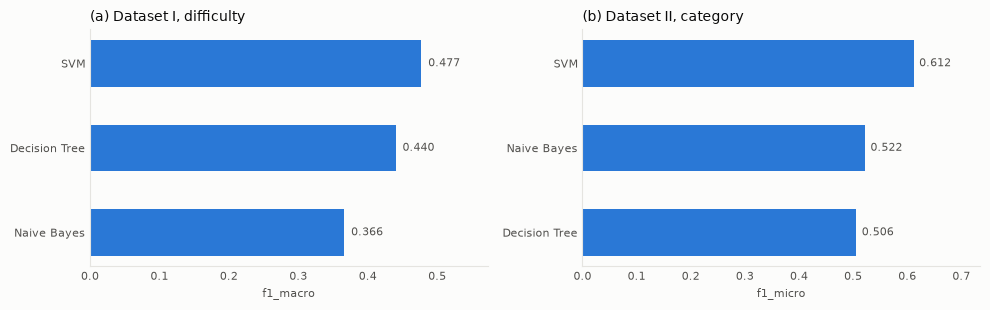

Selisih performa antar dataset
  SVM                    difficulty 0.477   category 0.612
  Decision Tree          difficulty 0.440   category 0.506
  Naive Bayes            difficulty 0.366   category 0.522


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), facecolor=SURFACE)
for ax, (tabel, kolom, judul) in zip(axes, [
        (hasil1, "f1_macro", "(a) Dataset I, difficulty"),
        (hasil2, "f1_micro", "(b) Dataset II, category")]):
    urut = tabel[kolom].sort_values()
    ax.barh(urut.index, urut.values, height=0.55, color="#2a78d6")
    for i, v in enumerate(urut.values):
        ax.text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=8, color=TEKS_SEKUNDER)
    ax.set_title(judul, fontsize=10, color=TEKS_UTAMA, loc="left")
    ax.set_xlim(0, max(urut.values) * 1.2)
    ax.set_xlabel(kolom, fontsize=8, color=TEKS_SEKUNDER)
    ax.set_facecolor(SURFACE)
    for sisi in ("top", "right"):
        ax.spines[sisi].set_visible(False)
    for sisi in ("left", "bottom"):
        ax.spines[sisi].set_color(GARIS)
    ax.tick_params(colors=TEKS_SEKUNDER, length=0, labelsize=8)
plt.tight_layout()
plt.show()

print("Selisih performa antar dataset")
for nama in hasil1.index:
    print(f"  {nama:<22} difficulty {hasil1.loc[nama, 'f1_macro']:.3f}   "
          f"category {hasil2.loc[nama, 'f1_micro']:.3f}")

**Penjelasan.** Membandingkan algoritma yang sama pada dua tugas yang sifatnya berbeda. Angka kedua panel tidak bisa dibandingkan langsung karena metriknya beda, tapi urutan algoritmanya bisa, dan itu memperlihatkan apakah algoritma yang unggul pada satu tugas juga unggul pada tugas lain.

## Mencari Parameter Terbaik

In [9]:
terbaik = hasil1.index[0]
grid = GridSearchCV(models()[terbaik], PARAMETER[terbaik],
                    cv=StratifiedKFold(LIPATAN, shuffle=True, random_state=SEED),
                    scoring="f1_macro", n_jobs=-1)

fitur = TfidfVectorizer(**PARAM_TFIDF)
X = fitur.fit_transform(ds1["clean"])
mulai = time.time()
grid.fit(X, ds1["Difficulty"])

print("Model yang dicari :", terbaik)
print("Kombinasi diuji   :", len(grid.cv_results_["params"]))
print("Waktu pencarian   :", f"{time.time() - mulai:.1f} detik\n")
print("Parameter terbaik :", grid.best_params_)
print("Macro F1 sesudah  :", f"{grid.best_score_:.3f}")
print("Macro F1 sebelum  :", f"{hasil1.loc[terbaik, 'f1_macro']:.3f}")

Model yang dicari : SVM
Kombinasi diuji   : 10
Waktu pencarian   : 0.5 detik

Parameter terbaik : {'C': 0.1, 'class_weight': 'balanced'}
Macro F1 sesudah  : 0.500
Macro F1 sebelum  : 0.477


**Penjelasan.** GridSearchCV mencoba seluruh kombinasi parameter dengan cross validation lima lipatan pada Dataset I. Angka sebelum dan sesudah dicetak berdampingan supaya kelihatan apakah pencarian parameter memang memberi perbaikan.

## Confusion Matrix dan Dokumen yang Salah Ditebak

In [10]:
fitur = TfidfVectorizer(**PARAM_TFIDF)
idx_latih, idx_uji = train_test_split(np.arange(len(ds1)), test_size=PORSI_UJI,
                                      random_state=SEED, stratify=ds1["Difficulty"])
X_latih = fitur.fit_transform(ds1["clean"].iloc[idx_latih])
X_uji = fitur.transform(ds1["clean"].iloc[idx_uji])

model = grid.best_estimator_
model.fit(X_latih, ds1["Difficulty"].iloc[idx_latih])
tebak = model.predict(X_uji)
y_uji = ds1["Difficulty"].iloc[idx_uji]

kelas = sorted(ds1["Difficulty"].unique())
cm = confusion_matrix(y_uji, tebak, labels=kelas)
print(pd.DataFrame(cm, index=kelas, columns=kelas).to_string())
print("\n" + classification_report(y_uji, tebak, zero_division=0))

periksa = pd.DataFrame({"Problem Name": ds1["Problem Name"].iloc[idx_uji].values,
                        "Label Asli": y_uji.values, "Prediksi": tebak})
salah = periksa[periksa["Label Asli"] != periksa["Prediksi"]]
print("Salah tebak:", len(salah), "dari", len(periksa), "soal uji\n")
print("Pasangan kelas paling sering tertukar")
for (a, b), n in (salah.groupby(["Label Asli", "Prediksi"]).size()
                  .sort_values(ascending=False).head(4).items()):
    print(f"  {a:<8} ditebak {b:<8} {n:>3} kali")
display(salah.head(6))

        Easy  Hard  Medium
Easy      82    15      71
Hard      24    49      84
Medium    66    64     202

              precision    recall  f1-score   support

        Easy       0.48      0.49      0.48       168
        Hard       0.38      0.31      0.34       157
      Medium       0.57      0.61      0.59       332

    accuracy                           0.51       657
   macro avg       0.48      0.47      0.47       657
weighted avg       0.50      0.51      0.50       657

Salah tebak: 324 dari 657 soal uji

Pasangan kelas paling sering tertukar
  Hard     ditebak Medium    84 kali
  Easy     ditebak Medium    71 kali
  Medium   ditebak Easy      66 kali
  Medium   ditebak Hard      64 kali


,Problem Name,Label Asli,Prediksi
0,Count Prefix and Suffix Pairs II,Hard,Easy
4,Preimage Size of Factorial Zeroes Function,Hard,Medium
5,Sort Even and Odd Indices Independently,Easy,Medium
6,String Compression,Medium,Easy
9,Ways to Split Array Into Good Subarrays,Medium,Hard
11,Analyze Organization Hierarchy,Hard,Easy


**Penjelasan.** Rata rata cross validation tidak memperlihatkan kelas mana yang gagal, jadi dipakai satu pembagian 80 banding 20 secara stratified. Pasangan kelas yang paling sering tertukar menunjukkan kelas mana yang batasnya tidak tegas di ruang fitur.

## Hasil Per Label Dataset II

In [11]:
fitur2 = TfidfVectorizer(**PARAM_TFIDF)
idx_l, idx_u = train_test_split(np.arange(len(ds2)), test_size=PORSI_UJI, random_state=SEED)
Xl = fitur2.fit_transform(ds2["clean"].iloc[idx_l])
Xu = fitur2.transform(ds2["clean"].iloc[idx_u])

nama_terbaik2 = hasil2.index[0]
model2 = bungkus(nama_terbaik2, models()[nama_terbaik2])
model2.fit(Xl, Y2[idx_l])
P = model2.predict(Xu)

baris = [{"Label": LABEL[i], "Support": int(Y2[idx_u][:, i].sum()),
          "Precision": round(precision_score(Y2[idx_u][:, i], P[:, i], zero_division=0), 3),
          "Recall": round(recall_score(Y2[idx_u][:, i], P[:, i], zero_division=0), 3),
          "F1": round(f1_score(Y2[idx_u][:, i], P[:, i], zero_division=0), 3)}
         for i in range(len(LABEL))]
per_label = pd.DataFrame(baris).sort_values("F1", ascending=False).reset_index(drop=True)
per_label.to_csv(HASIL / "tugas_perlabel_nb_svm_dt.csv", index=False)

print("Model:", nama_terbaik2)
print("Label dengan F1 nol:", int((per_label["F1"] == 0).sum()), "dari", len(LABEL))
display(per_label)

Model: SVM
Label dengan F1 nol: 0 dari 23


,Label,Support,Precision,Recall,F1
0,Binary Tree,23,1.000,0.957,0.978
1,Tree,34,0.969,0.912,0.939
2,String,158,0.936,0.924,0.930
3,Array,386,0.932,0.894,0.913
4,Matrix,49,0.825,0.959,0.887
5,Graph Theory,28,0.692,0.643,0.667
6,Depth-First Search,49,0.667,0.653,0.660
7,Math,135,0.562,0.600,0.581
8,Breadth-First Search,37,0.489,0.622,0.548
9,Hash Table,140,0.503,0.571,0.535


**Penjelasan.** Laporan per label memperlihatkan sebaran kemampuan yang tidak terlihat dari angka micro. Label dengan kosakata khas memperoleh F1 tinggi, sedangkan label yang kosakatanya tumpang tindih dengan banyak label lain bisa jatuh sampai nol.

## Pohon Keputusan yang Terbentuk

In [12]:
from sklearn.tree import export_text

fitur_dt = TfidfVectorizer(**PARAM_TFIDF)
X_dt = fitur_dt.fit_transform(ds1["clean"])
dt = models()["Decision Tree"]
dt.fit(X_dt, ds1["Difficulty"])

nama_fitur = list(fitur_dt.get_feature_names_out())
urut = np.argsort(-dt.feature_importances_)[:10]
print("Sepuluh kata yang paling sering dipakai memecah data\n")
for peringkat, j in enumerate(urut, 1):
    print(f"  {peringkat:>2}. {nama_fitur[j]:<22} {dt.feature_importances_[j]:.4f}")

print("\nEmpat tingkat teratas pohon keputusan\n")
teks_pohon = export_text(dt, feature_names=nama_fitur, max_depth=3)
print("\n".join(teks_pohon.split("\n")[:28]))

Sepuluh kata yang paling sering dipakai memecah data

   1. modulo                 0.0401
   2. possible               0.0362
   3. undirected             0.0319
   4. maximum                0.0281
   5. integer                0.0246
   6. otherwise              0.0244
   7. array                  0.0241
   8. format                 0.0217
   9. th                     0.0189
  10. one                    0.0187

Empat tingkat teratas pohon keputusan

|--- modulo <= 0.06
|   |--- undirected <= 0.06
|   |   |--- possible <= 0.03
|   |   |   |--- otherwise <= 0.08
|   |   |   |   |--- truncated branch of depth 17
|   |   |   |--- otherwise >  0.08
|   |   |   |   |--- truncated branch of depth 16
|   |   |--- possible >  0.03
|   |   |   |--- digit <= 0.18
|   |   |   |   |--- truncated branch of depth 17
|   |   |   |--- digit >  0.18
|   |   |   |   |--- truncated branch of depth 6
|   |--- undirected >  0.06
|   |   |--- node <= 0.30
|   |   |   |--- center <= 0.06
|   |   |   |   |--- 

**Penjelasan.** Decision Tree bisa ditampilkan sebagai aturan yang bisa dibaca manusia. Kata yang muncul di tingkat atas pohon adalah kata yang paling memisahkan data, dan ini memperlihatkan dasar keputusan model secara langsung tanpa perlu menebak.